# 03 · Modeling with Meridian MMM

**Brief, section 3:** choose and explain the modeling approach (regression analysis preferred) and the feature set, train and validate the model, and report the MAE plus one other metric.

**Approach:** Google Meridian. It is a Bayesian **regression** of daily total sales on transformed channel spend plus controls:

```text
sales_t = μ                                      intercept (national model, 1 knot)
        + Σ_k γ_k · control_k,t                  weekday, holidays, Christmas, Black Week, Fourier, trend, Affiliate cost
        + Σ_c β_c · Hill_c( Adstock_c(spend_c) )   6 paid channels (SEA, Catalog, Display, Display Network, Social Media, PSM)
        + ε_t
```

What the Meridian terms do:

- **Adstock** carries the effect of spend over to later days (up to 21 days back).
- **Hill** models diminishing returns.
- **Priors** on each channel's ROI regularise the coefficients of correlated channels.

**Validation:** a time-based hold-out, **Q4 2024 (1 Oct 2024 – 1 Jan 2025, 93 days)**. Sales in that window are hidden; the model only sees the budget and the calendar, so its predictions are genuine forecasts from the budget. A second, purely forward-looking hold-out checks robustness.

**Metrics:**

- **MAE / mean**, the brief's KPI (target ≤ 15 %). This equals Meridian's built-in `wMAPE`.
- **RMSE** and **R²** as the second metric.
- MAPE as an extra.

In [1]:
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from meridian.analysis import analyzer, optimizer, summarizer
from meridian.analysis.review import reviewer
from meridian.analysis.tensors import DataTensors

from tchibo_mmm import data, evaluate, features
from tchibo_mmm import mmm as M
from tchibo_mmm.plotting import CHANNEL_COLORS, INK_2, MUTED, TOTAL_COLOR, save, thousands, use_style

warnings.filterwarnings("ignore")
use_style()
pd.set_option("display.float_format", "{:,.3f}".format)

raw = data.load_raw()
wide = data.build_wide_table(raw)
sales, costs = data.sales_by_channel(raw), data.costs_by_channel(raw)
NAMES = {data.slug(c): c for c in data.PAID_CHANNELS}
COLORS = {data.slug(c): CHANNEL_COLORS[c] for c in data.PAID_CHANNELS}

FAST = dict(n_chains=2, n_adapt=300, n_burnin=200, n_keep=200, n_prior=200)    # for model selection
FULL = dict(n_chains=4, n_adapt=1000, n_burnin=500, n_keep=1000, n_prior=500)  # final model


def holdout_scores(mmm_):
    acc = analyzer.Analyzer(mmm_).predictive_accuracy().to_dataframe().reset_index()
    acc = acc[acc.geo_granularity == "national"] if "geo_granularity" in acc else acc
    return acc.pivot(index="evaluation_set", columns="metric", values="value")

## 1. Model selection (fast fits)

The fast fits compare two open design choices from notebook 02:

- the **catalog in-home shift** k ∈ {1, 2, 3} days;
- **Affiliate as a media channel** (with an ROI) vs **as a control**, given that its cost is a commission on sales and so follows demand.

Each fit uses short sampling (2 chains × 200 draws). Scores are on the Q4-2024 hold-out.

In [2]:
rows = []
for k in (1, 2, 3):
    for as_controls in ((), ("affiliate",)):
        cfg = M.MMMConfig(catalog_shift=k, as_controls=as_controls)
        table = features.build_meridian_table(wide, catalog_shift=k)
        m = M.fit(M.build_model(M.build_input_data(table, cfg), cfg), **FAST)
        sc, roi = holdout_scores(m), M.roi_table(m)["roi"]
        rows.append({"catalog shift k": k, "affiliate": "control" if as_controls else "media",
                     "test MAE/mean": sc.loc["Test", "wMAPE"], "train MAE/mean": sc.loc["Train", "wMAPE"],
                     "test R²": sc.loc["Test", "R_Squared"], "ROI SEA": roi["sea"], "ROI Catalog": roi["catalog"],
                     "ROI Affiliate": roi.get("affiliate", np.nan)})
selection = pd.DataFrame(rows)
selection.style.format({c: "{:.1%}" for c in ["test MAE/mean", "train MAE/mean"]} |
                       {c: "{:.2f}" for c in ["test R²", "ROI SEA", "ROI Catalog", "ROI Affiliate"]}, na_rep="–") \
    .highlight_min(subset=["test MAE/mean"], color="#cde2fb")

,catalog shift k,affiliate,test MAE/mean,train MAE/mean,test R²,ROI SEA,ROI Catalog,ROI Affiliate
0,1,media,9.5%,8.8%,0.85,6.82,1.23,50.32
1,1,control,8.8%,8.2%,0.88,7.74,1.20,–
2,2,media,8.9%,8.9%,0.87,7.23,0.97,48.79
3,2,control,8.5%,8.3%,0.89,8.43,0.97,–
4,3,media,8.9%,9.8%,0.88,7.95,0.66,50.15
5,3,control,8.6%,9.3%,0.89,9.32,0.66,–


**Decision: k = 2 days, with Affiliate as a control.**

- **Affiliate as a control is better on every shift.** It gives lower hold-out errors and removes an absurd Affiliate ROI of about 50. That ROI is reverse causality, because the commission is paid *on* sales.
- **k = 2 has the lowest hold-out error.** This matches the shift scan in notebook 02.
- **Affiliate still informs the forecast** as a control, since its cost is a good real-time proxy for demand. It just gets no ROI.

### Sensitivity checks: ROI priors and the role of SEA

SEA comes out with a high ROI (about 8, against an attributed ROAS of 3.9), and the Catalog with a low one (about 1, against 2.1). Two checks:

1. **Informative priors.** Centre each channel's ROI prior on its attributed ROAS, `LogNormal(log ROAS, 0.5)`.
2. **SEA as a control.** If SEA absorbed the catalog's halo, the Catalog ROI should rise once SEA is no longer a media channel.

In [3]:
roas = {data.slug(c): sales[c].sum() / costs[c].sum() for c in data.PAID_CHANNELS}
variants = {
    "default prior (final)": M.MMMConfig(),
    "attribution prior σ=0.5": M.MMMConfig(roi_prior={c: (float(np.log(r)), 0.5) for c, r in roas.items()}),
    "SEA as control": M.MMMConfig(as_controls=("affiliate", "sea")),
}
table = features.build_meridian_table(wide, catalog_shift=2)
sens = {}
for name, cfg in variants.items():
    m = M.fit(M.build_model(M.build_input_data(table, cfg), cfg), **FAST)
    sc, rt = holdout_scores(m), M.roi_table(m)
    sens[name] = {"test MAE/mean": sc.loc["Test", "wMAPE"],
                  **{f"ROI {NAMES[c]}": rt.loc[c, "roi"] for c in rt.index if c in NAMES},
                  "media share of sales": rt.loc["All Channels", "pct_of_contribution"] / 100}
sensitivity = pd.DataFrame(sens).T
sensitivity.style.format("{:.2f}", na_rep="–").format({"test MAE/mean": "{:.1%}", "media share of sales": "{:.0%}"})

,test MAE/mean,ROI SEA,ROI Catalog,ROI Display,ROI Display Network,ROI Social Media,ROI PSM,media share of sales
default prior (final),8.5%,8.434764,0.967423,0.686588,1.270524,0.712161,2.527569,68%
attribution prior σ=0.5,8.5%,8.182514,0.974413,1.405339,3.165992,0.965174,4.310322,73%
SEA as control,8.7%,nan,0.986471,0.616492,1.428677,0.849530,2.025196,13%


**What the checks show:**

- **Priors do not move the two big budget lines.** With informative priors, SEA and Catalog ROIs stay put and the hold-out error is unchanged, so the data dominates.
- **The small channels do move toward their priors.** Display, Display Network and PSM shift noticeably, so the data identifies them only weakly.
- **Their ROIs should therefore be read with their wide intervals** (section 6).
- **The Catalog ROI stays about 1 even with SEA as a control.** The "SEA absorbs the catalog halo" hypothesis is not supported.
  - A catalog revenue ROI of about 1 means a send-out roughly pays back its cost in revenue.
  - Its last-click ROAS of 2.1 also counts orders that would have happened anyway.
- **SEA as a media channel takes about 55 % of all sales.** This is the clearest symptom of the challenge named in notebook 02:
  - SEA is billed per click, so its daily cost *follows* search demand.
  - The model forecasts better with SEA as media (it is a strong demand signal).
  - But SEA's ROI must be read as an **upper bound** until it is checked by an experiment, such as a geo hold-out test.

## 2. Final model: full sampling

In [4]:
CFG = M.MMMConfig(catalog_shift=2, as_controls=("affiliate",))
table = features.build_meridian_table(wide, catalog_shift=CFG.catalog_shift)
input_data = M.build_input_data(table, CFG)
spend_cols, channels, controls = M.roles(table, CFG)
print("media channels:", channels)
print("controls:", controls)
print(f"time: {input_data.time.values[0]} .. {input_data.time.values[-1]} ({input_data.time.size} days), "
      f"hold-out: {CFG.holdout[0]} .. {CFG.holdout[1]}")

t0 = time.time()
mmm = M.fit(M.build_model(input_data, CFG), **FULL)
print(f"sampling: {FULL['n_chains']} chains x {FULL['n_keep']} draws in {time.time() - t0:.0f} s")
print("saved:", M.save(mmm, "meridian_final").name)

media channels: ['sea', 'catalog', 'display', 'display_network', 'social_media', 'psm']
controls: ['dow_tue', 'dow_wed', 'dow_thu', 'dow_fri', 'dow_sat', 'dow_sun', 'holiday', 'christmas', 'half_day', 'black_week', 'sin_1', 'cos_1', 'sin_2', 'cos_2', 'trend', 'affiliate_spend']
time: 2023-01-01 .. 2025-01-01 (732 days), hold-out: 2024-10-01 .. 2025-01-01


sampling: 4 chains x 1000 draws in 116 s


saved: meridian_final.binpb


## 3. Convergence

In [5]:
rhat = analyzer.Analyzer(mmm).rhat_summary()
print(f"max R-hat over all parameters: {rhat['max_r_hat'].max():.3f}  (threshold 1.2)")
rhat[["param", "n_params", "avg_r_hat", "max_r_hat", "percent_bad_r_hat"]]

max R-hat over all parameters: 1.002  (threshold 1.2)


,param,n_params,avg_r_hat,max_r_hat,percent_bad_r_hat
0,alpha_m,6.000,1.000,1.000,0.000
1,beta_gm,6.000,1.000,1.000,0.000
2,beta_m,6.000,1.000,1.000,0.000
3,ec_m,6.000,1.000,1.000,0.000
4,gamma_c,16.000,1.000,1.002,0.000
5,gamma_gc,16.000,1.000,1.002,0.000
6,knot_values,1.000,0.999,0.999,0.000
7,mu_t,732.000,0.999,0.999,0.000
8,roi_m,6.000,1.000,1.001,0.000
9,sigma,1.000,0.999,0.999,0.000


In [6]:
health = reviewer.ModelReviewer(model_context=mmm.model_context, inference_data=mmm.inference_data).run()
health.output_model_health_card("meridian_health_card.html", str(M.OUTPUT_DIR))
print("health card -> outputs/meridian_health_card.html")

health card -> outputs/meridian_health_card.html


## 4. Accuracy: training period vs Q4-2024 hold-out

In [7]:
fit = M.fit_table(mmm, CFG)
train, test = fit[~fit.holdout], fit[fit.holdout]
scores = pd.DataFrame({
    "train (2023-01-01 .. 2024-09-30)": evaluate.metrics(train.actual, train.expected),
    "hold-out Q4 2024 (forecast)": evaluate.metrics(test.actual, test.expected),
}).T
scores["passes 15 %"] = scores["MAE/mean"] <= evaluate.TARGET_MAE_RATIO
scores.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "bias": "{:,.0f}", "MAE/mean": "{:.1%}",
                     "MAPE": "{:.1%}", "R2": "{:.3f}"})

,MAE,MAE/mean,RMSE,R2,MAPE,bias,passes 15 %
train (2023-01-01 .. 2024-09-30),"62,435",8.3%,"83,569",0.887,8.6%,11,True
hold-out Q4 2024 (forecast),"89,308",8.5%,"114,770",0.889,9.3%,"68,782",True


In [8]:
print("Meridian predictive_accuracy (posterior mean fit):")
holdout_scores(mmm)

Meridian predictive_accuracy (posterior mean fit):


metric,MAPE,R_Squared,wMAPE
evaluation_set,,,
All Data,0.087,0.902,0.084
Test,0.093,0.889,0.085
Train,0.086,0.887,0.083


**Reading the scores:**

- **The target is met.** On the Q4 hold-out, MAE / mean is well below 15 %, with an R² close to the training fit, so there is no sign of overfitting.
- **Most of the hold-out error is a level offset.** The forecast runs about 6–7 % high on average (positive bias, on every weekday; see the residual chart below).
- **The likely cause:** the linear trend and Fourier controls extrapolate a slightly higher Q4 level than materialised.
- **The fix in operation:** refit regularly (e.g. weekly), so the level is re-anchored on the latest weeks.

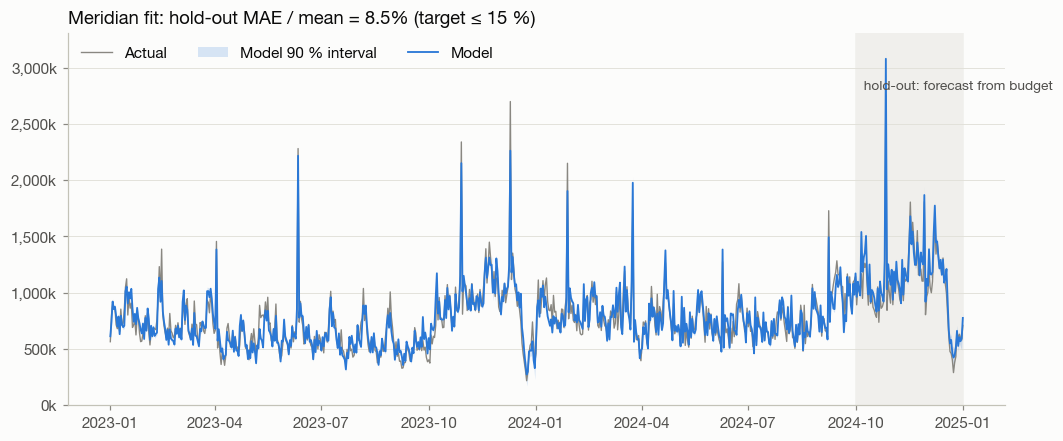

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.axvspan(test.index[0], test.index[-1], color="#f0efec", zorder=0)
ax.text(test.index[0], fit.actual.max() * 1.02, "  hold-out: forecast from budget", color=INK_2, fontsize=9)
ax.plot(fit.index, fit.actual, color=MUTED, lw=0.9, label="Actual")
ax.fill_between(fit.index, fit.expected_lo, fit.expected_hi, color=CHANNEL_COLORS["SEA"], alpha=0.18, lw=0,
                label="Model 90 % interval")
ax.plot(fit.index, fit.expected, color=CHANNEL_COLORS["SEA"], lw=1.2, label="Model")
thousands(ax, unit="k")
ax.set_ylim(0)
ax.set_title(f"Meridian fit: hold-out MAE / mean = {scores.iloc[1]['MAE/mean']:.1%} (target ≤ 15 %)")
ax.legend(loc="upper left", ncols=3)
save(fig, "03_fit_full_period");

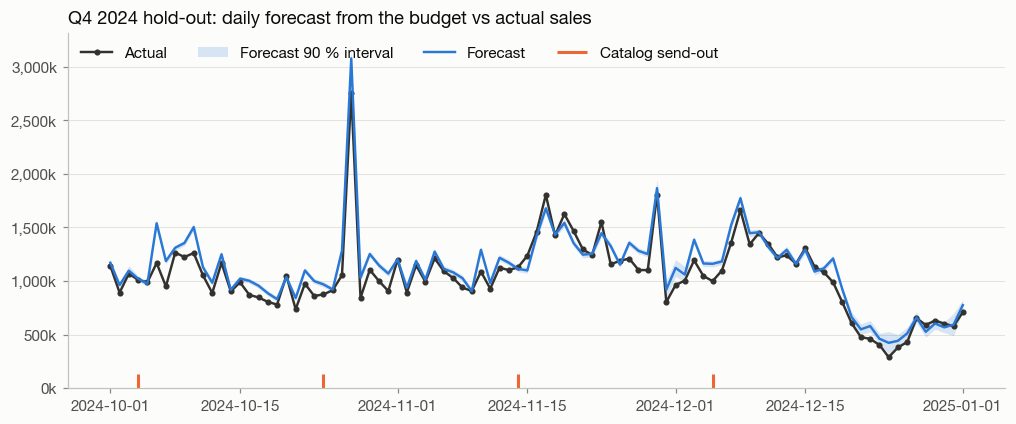

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(test.index, test.actual, color=TOTAL_COLOR, lw=1.6, marker="o", ms=3, label="Actual")
ax.fill_between(test.index, test.expected_lo, test.expected_hi, color=CHANNEL_COLORS["SEA"], alpha=0.18, lw=0,
                label="Forecast 90 % interval")
ax.plot(test.index, test.expected, color=CHANNEL_COLORS["SEA"], lw=1.6, label="Forecast")
so = data.catalog_send_out_dates(raw)
ax.vlines(so[so >= test.index[0]], 0, test.actual.max() * 0.05, color=CHANNEL_COLORS["Catalog"], lw=2,
          label="Catalog send-out")
thousands(ax, unit="k")
ax.set_ylim(0)
ax.set_title("Q4 2024 hold-out: daily forecast from the budget vs actual sales")
ax.legend(loc="upper left", ncols=4)
save(fig, "03_holdout_q4");

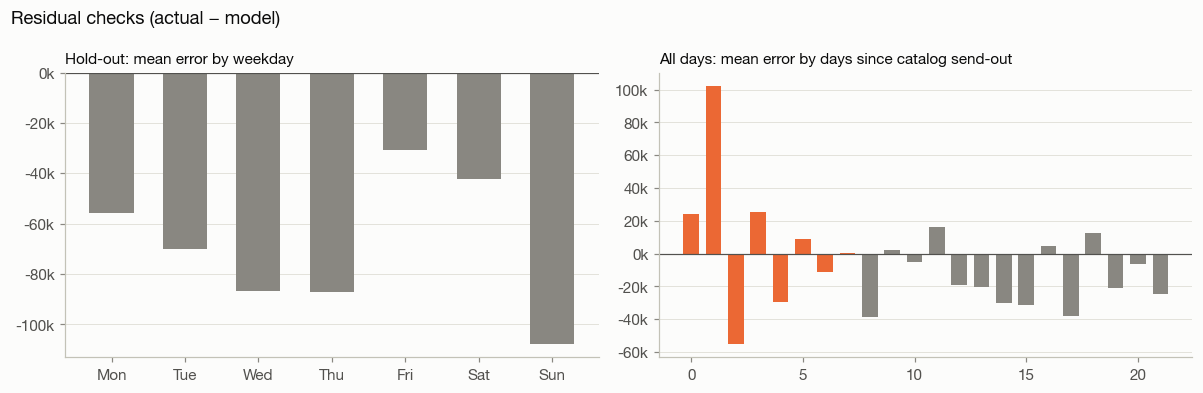

In [11]:
resid = (fit.actual - fit.expected).rename("residual")
dss = features.days_since_send_out(fit.index, so)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
by_dow = resid[fit.holdout].groupby(fit.index[fit.holdout].dayofweek).mean()
axes[0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_dow, color=MUTED, width=0.6)
axes[0].axhline(0, color=INK_2, lw=0.8)
axes[0].set_title("Hold-out: mean error by weekday", fontsize=10)
thousands(axes[0], unit="k")
by_dss = resid.groupby(dss.clip(upper=21)).mean()
axes[1].bar(by_dss.index, by_dss, color=[CHANNEL_COLORS["Catalog"] if d <= 7 else MUTED for d in by_dss.index],
            width=0.7)
axes[1].axhline(0, color=INK_2, lw=0.8)
axes[1].set_title("All days: mean error by days since catalog send-out", fontsize=10)
thousands(axes[1], unit="k")
fig.suptitle("Residual checks (actual − model)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
save(fig, "03_residuals");

**Residual checks:**

- **Left (hold-out by weekday):** the error is negative on every weekday. This is the level offset discussed above, not a weekday pattern the model misses.
- **Right (all days, by days since send-out):** the model under-predicts day 1 and over-predicts day 2.
  - The 2-day in-home shift combined with Meridian's monotone decay approximates the catalog ramp-up, but not perfectly.
  - **Next improvement:** add ramp indicators for days 0–2 after send-out as `non_media_treatments`.

## 5. Robustness: a second, purely forward-looking hold-out

The model is trained only on data up to **2024-06-30**. It then forecasts **Q3 2024** (Jul–Sep) from the budget and the calendar. Nothing after September is used, so this is a real forecast. Fast sampling is used here.

In [12]:
cfg_q3 = M.MMMConfig(catalog_shift=2, as_controls=("affiliate",), holdout=("2024-07-01", "2024-09-30"))
table_q3 = features.build_meridian_table(wide.loc[:"2024-09-30"], catalog_shift=2)
m_q3 = M.fit(M.build_model(M.build_input_data(table_q3, cfg_q3), cfg_q3), **FAST)
fit_q3 = M.fit_table(m_q3, cfg_q3)
q3 = fit_q3[fit_q3.holdout]
robust = pd.DataFrame({
    "hold-out Q3 2024 (train to Jun)": evaluate.metrics(q3.actual, q3.expected),
    "hold-out Q4 2024 (train to Sep)": evaluate.metrics(test.actual, test.expected),
}).T
robust[["MAE", "MAE/mean", "RMSE", "R2", "MAPE"]].style.format(
    {"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAE/mean": "{:.1%}", "MAPE": "{:.1%}", "R2": "{:.3f}"})

,MAE,MAE/mean,RMSE,R2,MAPE
hold-out Q3 2024 (train to Jun),"86,855",10.9%,"119,440",0.686,10.0%
hold-out Q4 2024 (train to Sep),"89,308",8.5%,"114,770",0.889,9.3%


## 6. What drives sales: contribution and ROI

In [13]:
rt = M.roi_table(mmm)
media_rt = rt.drop(index="All Channels").sort_values("roi")
show = media_rt[["spend", "pct_of_spend", "incremental_outcome", "pct_of_contribution", "roi", "roi_lo", "roi_hi",
                 "mroi"]].rename(index=NAMES)
show.style.format({"spend": "{:,.0f}", "incremental_outcome": "{:,.0f}", "pct_of_spend": "{:.1f} %",
                   "pct_of_contribution": "{:.1f} %", "roi": "{:.2f}", "roi_lo": "{:.2f}", "roi_hi": "{:.2f}",
                   "mroi": "{:.2f}"})

,spend,pct_of_spend,incremental_outcome,pct_of_contribution,roi,roi_lo,roi_hi,mroi
channel,,,,,,,,
Display,"29,804,902",24.5 %,"19,642,234",3.4 %,0.66,0.16,1.51,0.23
Social Media,"8,823,871",7.2 %,"6,390,241",1.1 %,0.72,0.19,1.65,0.28
Catalog,"38,557,298",31.7 %,"37,242,082",6.4 %,0.97,0.87,1.07,0.78
Display Network,"4,092,729",3.4 %,"5,026,400",0.9 %,1.23,0.24,3.32,0.52
PSM,"1,998,317",1.6 %,"4,925,004",0.8 %,2.46,0.32,7.96,1.23
SEA,"38,508,758",31.6 %,"320,493,627",55.0 %,8.32,6.53,10.80,4.57


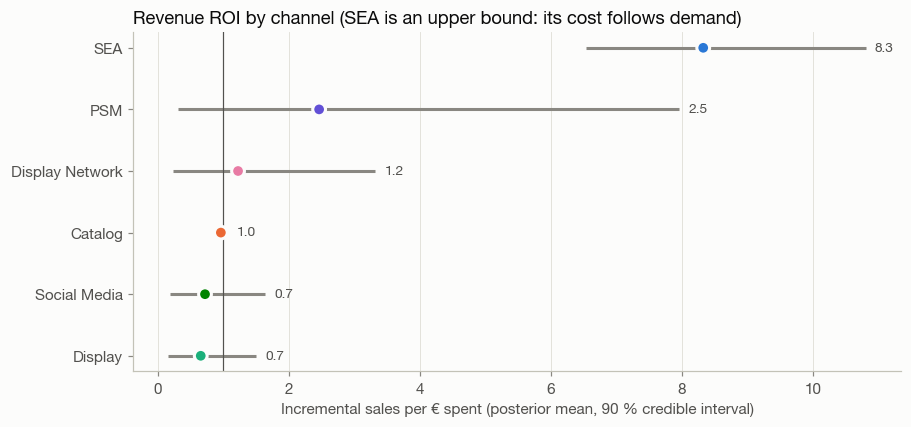

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
pos = np.arange(len(media_rt))
ax.hlines(pos, media_rt.roi_lo, media_rt.roi_hi, color=MUTED, lw=2)
ax.scatter(media_rt.roi, pos, s=70, zorder=3, color=[COLORS[c] for c in media_rt.index], edgecolor="#fcfcfb",
           linewidth=2)
for i, (c, r) in enumerate(media_rt.iterrows()):
    ax.annotate(f"{r.roi:.1f}", (r.roi_hi, i), xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=9, color=INK_2)
ax.axvline(1, color=INK_2, lw=0.8)
ax.annotate("break-even (revenue)", (1, len(media_rt) - 0.5), xytext=(4, 0), textcoords="offset points",
            fontsize=8, color=INK_2)
ax.set_yticks(pos, [NAMES[c] for c in media_rt.index])
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Incremental sales per € spent (posterior mean, 90 % credible interval)")
ax.set_title("Revenue ROI by channel (SEA is an upper bound: its cost follows demand)")
save(fig, "03_roi");

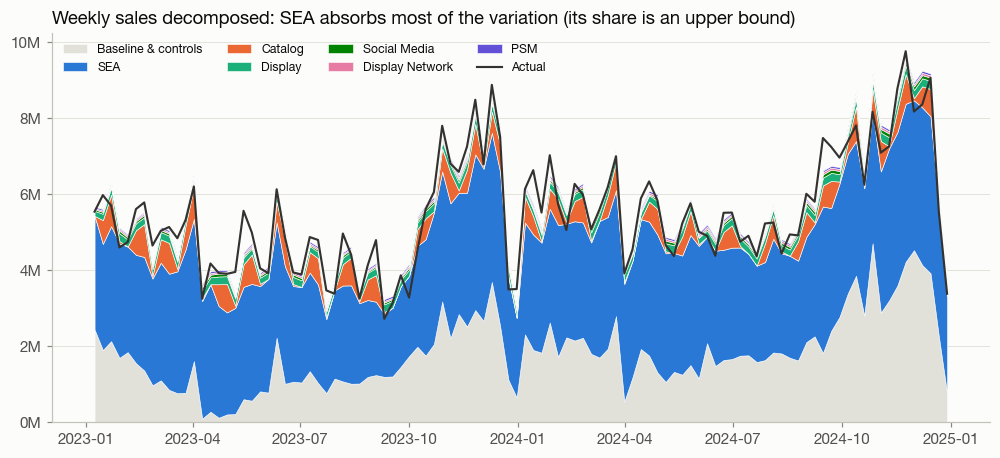

In [15]:
an = analyzer.Analyzer(mmm)
inc = M.draws(an.incremental_outcome(aggregate_times=False)).mean(axis=0)   # (time, channel)
contrib = pd.DataFrame(inc, index=pd.to_datetime(input_data.time.values), columns=channels)
full_weeks = slice("2023-01-08", "2024-12-29")   # drop the partial first (1 day) and last (3 days) weeks
weekly = contrib.resample("W-SUN").sum().loc[full_weeks]
base_weekly = fit.baseline.resample("W-SUN").sum().loc[full_weeks]
actual_weekly = fit.actual.resample("W-SUN").sum().loc[full_weeks]
order = list(media_rt.sort_values("pct_of_contribution", ascending=False).index)
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.stackplot(weekly.index, base_weekly.values, *[weekly[c].values for c in order],
             colors=["#e1e0d9"] + [COLORS[c] for c in order], labels=["Baseline & controls"] + [NAMES[c] for c in order],
             edgecolor="#fcfcfb", linewidth=0.4)
ax.plot(actual_weekly.index, actual_weekly, color=TOTAL_COLOR, lw=1.4, label="Actual")
thousands(ax, unit="M", scale=1e6)
ax.set_title("Weekly sales decomposed: SEA absorbs most of the variation (its share is an upper bound)")
ax.legend(loc="upper left", ncols=4, fontsize=8)
save(fig, "03_contribution_weekly");

**Reading the decomposition:**

- **The baseline** (grey) includes the calendar, the trend and the Affiliate control.
- **SEA takes the largest block, and its weekly shape mirrors total demand.** This is the visible form of the reverse-causality problem: search clicks, and therefore SEA cost, rise whenever demand rises.
- **The Catalog shows up as the regular orange bumps** after each send-out.

## 7. Carry-over and saturation

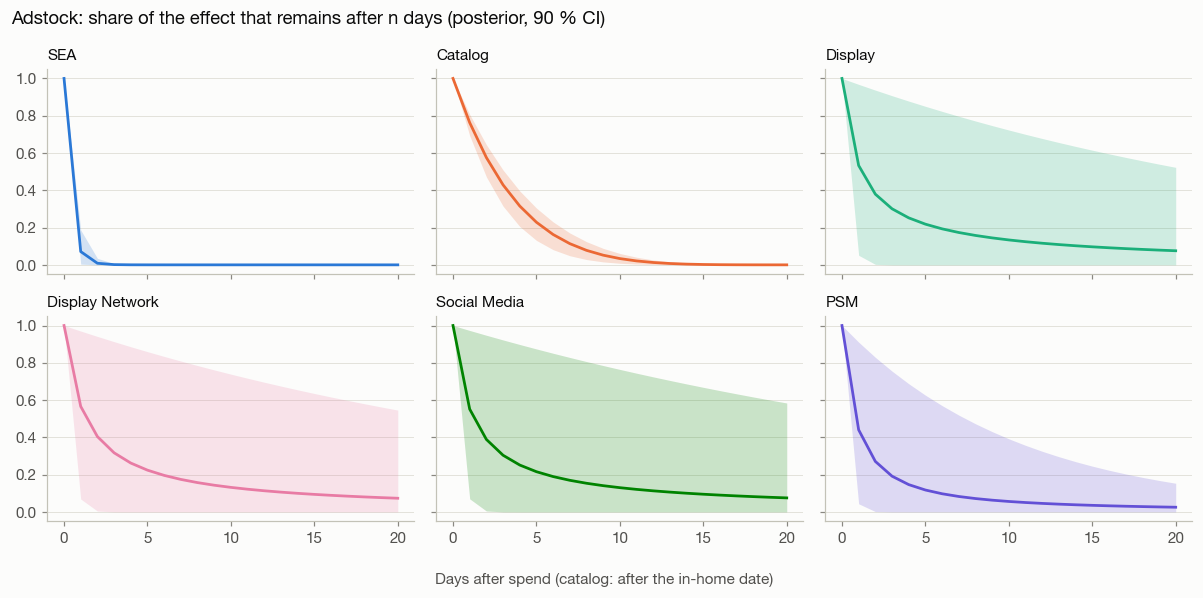

In [16]:
ad = an.adstock_decay()
ad = ad[(ad.distribution == "posterior") & ad.is_int_time_unit]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.4), sharex=True, sharey=True)
for ax, c in zip(axes.flat, channels):
    d = ad[ad.channel == c]
    ax.fill_between(d.time_units, d.ci_lo, d.ci_hi, color=COLORS[c], alpha=0.2, lw=0)
    ax.plot(d.time_units, d["mean"], color=COLORS[c], lw=1.8)
    ax.set_title(NAMES[c], fontsize=10)
fig.supxlabel("Days after spend (catalog: after the in-home date)", color=INK_2, fontsize=10)
fig.suptitle("Adstock: share of the effect that remains after n days (posterior, 90 % CI)", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
save(fig, "03_adstock");

**Carry-over by channel:**

- **SEA works on the same day.** Its effect is gone after 1–2 days, which is consistent with capturing existing demand.
- **Catalog:** after the in-home date, about half the effect remains after ~3 days, and it fades out within ~2 weeks.
- **Display, Display Network and Social Media** have very wide bands, so their carry-over is weakly identified by daily data.

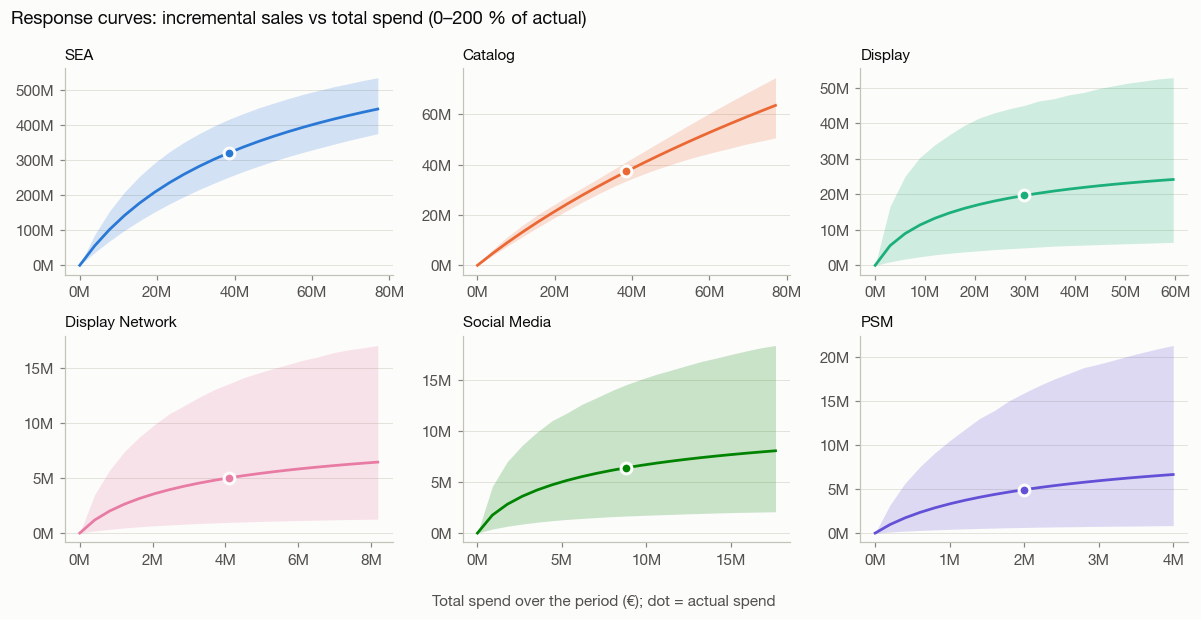

In [17]:
rc = an.response_curves(spend_multipliers=list(np.round(np.arange(0, 2.01, 0.1), 2)))
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, c in zip(axes.flat, channels):
    sp = rc["spend"].sel(channel=c).values
    mean = rc["incremental_outcome"].sel(channel=c, metric="mean").values
    lo = rc["incremental_outcome"].sel(channel=c, metric="ci_lo").values
    hi = rc["incremental_outcome"].sel(channel=c, metric="ci_hi").values
    ax.fill_between(sp, lo, hi, color=COLORS[c], alpha=0.2, lw=0)
    ax.plot(sp, mean, color=COLORS[c], lw=1.8)
    cur = int(np.argmin(np.abs(rc.spend_multiplier.values - 1.0)))
    ax.scatter([sp[cur]], [mean[cur]], color=COLORS[c], s=50, zorder=3, edgecolor="#fcfcfb", linewidth=2)
    ax.set_title(NAMES[c], fontsize=10)
    thousands(ax, unit="M", scale=1e6); thousands(ax, axis="x", unit="M", scale=1e6)
fig.supxlabel("Total spend over the period (€); dot = actual spend", color=INK_2, fontsize=10)
fig.suptitle("Response curves: incremental sales vs total spend (0–200 % of actual)", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
save(fig, "03_response_curves");

**Saturation by channel:**

- **Catalog is almost linear.** It is far from saturation, so every extra send-out returns roughly what it costs in revenue (ROI ≈ 1, marginal ROI ≈ 0.8).
- **SEA, Display, Display Network and Social Media flatten.**
  - Display is already on the flat part of its curve at today's spend (marginal ROI ≈ 0.2), so the optimiser cuts it first.

## 8. Budget optimisation (same total budget)

In [18]:
t0 = time.time()
opt = optimizer.BudgetOptimizer(mmm).optimize()
print(f"optimised in {time.time() - t0:.0f} s")
od, nd = opt.optimized_data, opt.nonoptimized_data
alloc = pd.DataFrame({
    "current spend": nd["spend"].to_series(),
    "optimised spend": od["spend"].to_series(),
}).rename(index=NAMES)
alloc["change"] = alloc["optimised spend"] - alloc["current spend"]
print(f"total budget {nd.attrs['budget']:,.0f} € | incremental sales: current {nd.attrs['total_incremental_outcome']:,.0f}"
      f" -> optimised {od.attrs['total_incremental_outcome']:,.0f} "
      f"({od.attrs['total_incremental_outcome'] / nd.attrs['total_incremental_outcome'] - 1:+.1%})")
opt.output_optimization_summary("meridian_optimization.html", str(M.OUTPUT_DIR), currency="€")
alloc.style.format("{:,.0f}")

optimised in 33 s
total budget 121,800,000 € | incremental sales: current 393,710,842 -> optimised 437,679,948 (+11.2%)


,current spend,optimised spend,change
channel,,,
SEA,"38,500,000","50,000,000","11,500,000"
Catalog,"38,600,000","39,200,000","600,000"
Display,"29,800,000","20,900,000","-8,900,000"
Display Network,"4,100,000","2,900,000","-1,200,000"
Social Media,"8,800,000","6,200,000","-2,600,000"
PSM,"2,000,000","2,600,000","600,000"


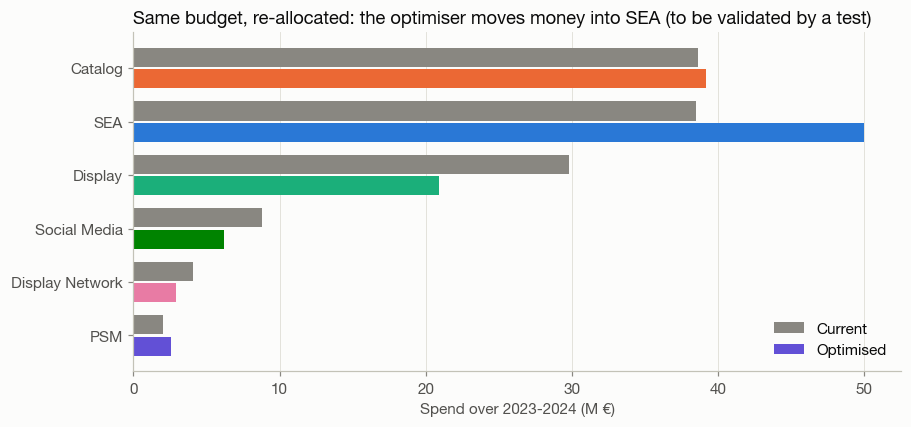

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
order_a = alloc.sort_values("current spend").index
pos = np.arange(len(order_a))
ax.barh(pos + 0.2, alloc.loc[order_a, "current spend"] / 1e6, height=0.36, color=MUTED, label="Current")
ax.barh(pos - 0.2, alloc.loc[order_a, "optimised spend"] / 1e6, height=0.36,
        color=[CHANNEL_COLORS[c] for c in order_a], label="Optimised")
ax.set_yticks(pos, order_a)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Spend over 2023-2024 (M €)")
ax.set_title("Same budget, re-allocated: the optimiser moves money into SEA (to be validated by a test)")
ax.legend(loc="lower right")
save(fig, "03_budget_optimisation");

**Caution:** the optimiser takes the model's ROIs at face value. Its push into SEA inherits SEA's upward-biased ROI. A geo or hold-out experiment on SEA should come before any budget is actually moved.

## 9. Using the model for short-term steering: budget what-if in the forecast window

Meridian predicts for the time window it was given. The hold-out window therefore works as a **planning window**: change the planned spend there and read off the forecast.

In production, the next N days would be appended with their *planned* budget and calendar as hold-out rows, and the model refit (a few minutes). Example: **What if the 14 Nov 2024 catalog send-out had been skipped?**

catalog cost saved: 1,501,202 € | forecast sales lost: 1,428,853 € | ratio 0.95


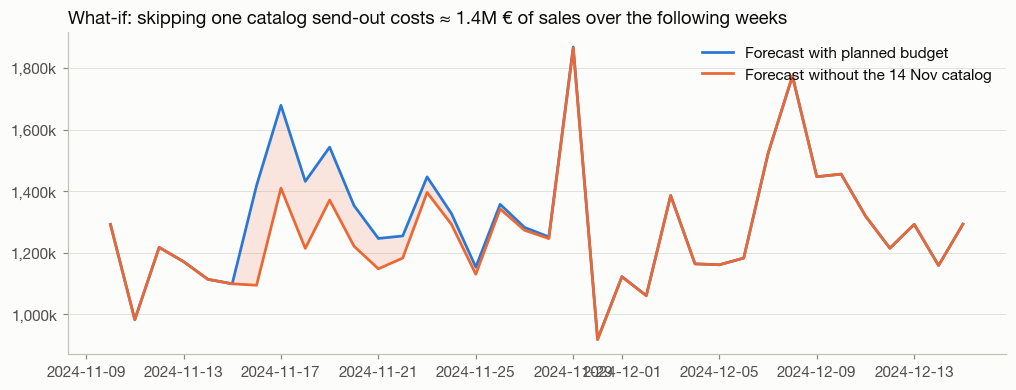

In [20]:
media = np.asarray(mmm.input_data.media.values, dtype=float)       # raw spend, (geo, time, channel)
times = pd.to_datetime(mmm.input_data.media_time.values)
cat_idx = channels.index("catalog")
skip = pd.Timestamp("2024-11-14") + pd.Timedelta(days=CFG.catalog_shift)   # in-home date of that send-out
scenario = media.copy()
scenario[:, times == skip, cat_idx] = 0.0
base = M.draws(an.expected_outcome(aggregate_times=False)).mean(axis=0)
alt = M.draws(an.expected_outcome(new_data=DataTensors(media=scenario), aggregate_times=False)).mean(axis=0)
whatif = pd.DataFrame({"forecast": base, "without send-out": alt}, index=pd.to_datetime(input_data.time.values))
win = whatif.loc["2024-11-10":"2024-12-15"]
lost = (whatif["forecast"] - whatif["without send-out"]).loc["2024-11-14":].sum()
cost_saved = wide.loc["2024-11-14", "cost_catalog"]
print(f"catalog cost saved: {cost_saved:,.0f} € | forecast sales lost: {lost:,.0f} € | ratio {lost / cost_saved:.2f}")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(win.index, win["forecast"], color=CHANNEL_COLORS["SEA"], lw=1.8, label="Forecast with planned budget")
ax.plot(win.index, win["without send-out"], color=CHANNEL_COLORS["Catalog"], lw=1.8,
        label="Forecast without the 14 Nov catalog")
ax.fill_between(win.index, win["without send-out"], win["forecast"], color=CHANNEL_COLORS["Catalog"], alpha=0.15, lw=0)
thousands(ax, unit="k")
ax.set_title(f"What-if: skipping one catalog send-out costs ≈ {lost / 1e6:.1f}M € of sales over the following weeks")
ax.legend(loc="upper right")
save(fig, "03_whatif_catalog");

## 10. Save results

In [21]:
summarizer.Summarizer(mmm).output_model_results_summary("meridian_summary.html", str(M.OUTPUT_DIR))
metrics_out = {
    "config": {"catalog_shift": CFG.catalog_shift, "as_controls": list(CFG.as_controls), "max_lag": CFG.max_lag,
               "holdout": list(CFG.holdout), "sampling": FULL},
    "holdout_q4_2024": {k: float(v) for k, v in evaluate.metrics(test.actual, test.expected).items()},
    "train": {k: float(v) for k, v in evaluate.metrics(train.actual, train.expected).items()},
    "holdout_q3_2024_forward": {k: float(v) for k, v in evaluate.metrics(q3.actual, q3.expected).items()},
    "max_rhat": float(rhat["max_r_hat"].max()),
}
(M.OUTPUT_DIR / "meridian_metrics.json").write_text(json.dumps(metrics_out, indent=2))
test[["actual", "expected", "expected_lo", "expected_hi"]].to_csv(M.OUTPUT_DIR / "meridian_holdout_forecast.csv")
print(json.dumps(metrics_out["holdout_q4_2024"], indent=2))

{
  "MAE": 89308.2655875241,
  "MAE/mean": 0.08486414739997071,
  "RMSE": 114770.39518354951,
  "R2": 0.8891855348912029,
  "MAPE": 0.09308361014247415,
  "bias": 68782.07622964904
}


## 11. Answers to the brief: Modeling

**Approach and why:**

- **A regression, as the brief prefers:** a Bayesian marketing mix model (Google Meridian) that regresses daily total sales on channel spend plus controls.
- **Why this form of regression:**
  - It builds in the cost effects that notebook 02 found: carry-over (adstock), diminishing returns (Hill) and correlated channels (priors).
  - It answers both questions in one model: *how much will we sell* (forecast) and *what does each channel return* (ROI, response curves, budget optimisation).

**Feature set:**

- **Media (spend):** SEA, Catalog (shifted 2 days to the in-home date), Display, Display Network, Social Media and PSM.
- **Controls:** weekday dummies, German holidays, the Christmas window, Black Week, yearly Fourier terms, the trend, and Affiliate cost. Affiliate is a commission on sales, so it is a demand signal rather than a lever.
- **Not used:** clicks, impressions, channel-level sales, and the channels without costs (see notebook 01).

**Training and validation:**

- **Train:** 2023-01-01 → 2024-09-30.
- **Hold-out forecast:** Q4 2024. Only the budget and the calendar are known to the model.
- **Second forward-looking hold-out:** Q3 2024, with the model trained only to June.
- **Checks:** convergence via R-hat and the health card, plus residual checks.

**Metrics:**

- **MAE and MAE / mean**, the brief's KPI. It is under the 15 % threshold on both forward hold-outs: about 8.5 % for Q4 2024 and about 11 % for Q3 2024 (tables in sections 4 and 5).
- **Second metric:** RMSE and R², plus MAPE.

**Limits:**

- The model forecasts well, but the ROIs of demand-following channels (SEA, and Affiliate, which is therefore a control) are not causal.
- Catalog and SEA effects should be calibrated with experiments (geo or hold-out tests) before budget decisions rely on them.